# Class-wise truncated-parabola regularization

A TP companion to [`simplex-lda/Synthetic_SIGReg.ipynb`](../simplex-lda/Synthetic_SIGReg.ipynb).
Keep its three Gaussian **input** classes, nonlinear encoder, matched initialization
and batch order, and snapshots at epochs 1, 5, 10, and 100. The **embedding** targets
are now normalized spherical truncated parabolas (Epanechnikov distributions)
centered at fixed simplex vertices.

Compare **FYLoss** and **TPRegFYLoss**. TPReg adapts LeJEPA's
random-projection characteristic-function matching to the TP law; it is not the
Gaussian SIGReg objective. The integration window remains positive and Gaussian,
but the target CF is dimension-dependent TP. Train on all training examples;
there is no calibration stage.

Run from `EDA/` with PyTorch, NumPy, and Matplotlib installed. Training can take
several minutes on a GPU; the settings below can be reduced for a smoke run.

## Setup and experiment settings

In [1]:
import json
import math
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset

from qgda import (
    SimplexQGaussianHead, qgaussian_joint_fy_loss, ClasswiseQGaussianReg,
)

TRAIN_SIZE, TEST_SIZE = 20_000, 4_000
BATCH_SIZE, EVAL_BATCH_SIZE = 256, 1024
PLOT_SIZE = 1000
checkpoint_epochs = (1, 5, 10, 100)
comparison_seed = 7
tp_weight = 1.0
num_slices = 256
num_integration_points = 65
diagnostic_integration_points = 129
tpreg_warmup_epochs = 5
tpreg_ramp_epochs = 5
TP_SHAPE_RULE = 'pi^(D/2) / (2 * Gamma(D/2 + 2)) * (1 + 4/D)^(D/2 + 1) * I_D'
loss_names = ('FYLoss', 'TPRegFYLoss')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
output_dir = Path('results/synthetic_tpreg')
plot_dir = Path('plots')
print('device =', device)

device = cuda


## The same synthetic input data

In [2]:
C, separation = 3, 1.7
NUM_CLASSES, D = C, 2
LABEL_OFFSET = 1
pi = torch.full((C,), 1 / C)
base_mus = torch.tensor([[-2.0, -0.5], [2.2, 0.2], [-0.5, 2.3]])
mus = base_mus * separation
input_covariance = torch.tensor([[1.0, 0.35], [0.35, 1.1]])
chol = torch.linalg.cholesky(input_covariance)


def sample_dataset(n_total, seed):
    generator = torch.Generator().manual_seed(seed)
    labels = torch.multinomial(pi, n_total, replacement=True, generator=generator)
    noise = torch.randn(n_total, 2, generator=generator)
    x = noise @ chol.T + mus[labels]
    order = torch.randperm(n_total, generator=generator)
    return x[order], (labels + LABEL_OFFSET)[order]


train_X, train_y = sample_dataset(TRAIN_SIZE, seed=7)
test_X, test_y = sample_dataset(TEST_SIZE, seed=137)
train_ds = TensorDataset(train_X, train_y)
test_ds = TensorDataset(test_X, test_y)
test_ld = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False,
                     generator=torch.Generator().manual_seed(137))
print('Training:', len(train_ds), 'Test:', len(test_ds))

Training: 20000 Test: 4000


## Fixed simplex TP head and nonlinear encoder

In [3]:
class DeepTPDA(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, D))
        self.head = SimplexQGaussianHead(C, D, q=0.0)  # Fixed dimension-dependent TP shape matrix.

    def forward(self, x):
        return self.head(self.encoder(x))


reference_head = SimplexQGaussianHead(C, D, q=0.0)
print('TP shape rule:', TP_SHAPE_RULE)
print('TP shape matrix:', reference_head.covariance)
print('TP moment covariance:', reference_head.moment_covariance)
print('Support radius:', reference_head.support_radius.item())

# For this D=2 experiment, the new shape rule gives these exact targets.
if D == 2:
    torch.testing.assert_close(reference_head.covariance, torch.eye(D) * (9 * math.pi / 4))
    torch.testing.assert_close(reference_head.moment_covariance, torch.eye(D) / 2)
    torch.testing.assert_close(reference_head.support_radius, torch.tensor(math.sqrt(3)))
print('Minimum mean distance:', torch.pdist(reference_head.mu).min().item())
print('Supports disjoint:', bool(torch.pdist(reference_head.mu).min() > 2 * reference_head.support_radius))

TP shape rule: pi^(D/2) / (2 * Gamma(D/2 + 2)) * (1 + 4/D)^(D/2 + 1) * I_D
TP shape matrix: tensor([[7.0686, 0.0000],
        [0.0000, 7.0686]])
TP moment covariance: tensor([[0.5000, 0.0000],
        [0.0000, 0.5000]])
Support radius: 1.7320507764816284
Minimum mean distance: 6.0
Supports disjoint: True


## Deriving the TP target for projected CF matching

Use the shared, fixed spherical TP shape matrix from `SimplexQGaussianHead(q=0)`:

$$
\Sigma=v_D I_D,\qquad
v_D=\frac{\pi^{D/2}}{2\Gamma(D/2+2)}
\left(1+\frac{4}{D}\right)^{D/2+1}.
$$

EDA parameterizes a class density as

$$
p(z\mid c)=\left[-\tau-\frac{\lVert z-\mu_c\rVert^2}{2v_D}\right]_+,
\qquad [x]_+=\max(x,0),
$$

$$
-\tau=\left[\frac{\Gamma(D/2+2)}{(2\pi v_D)^{D/2}}\right]^{2/(D+2)},
\qquad R^2=-2\tau v_D.
$$

The quadratic **shape** matrix $\Sigma$ is distinct from the actual moment
covariance:

$$
\operatorname{Cov}(Z\mid c)=\frac{R^2}{D+4}I_D.
$$

For this notebook's $D=2$ experiment, these values simplify to

$$
v_2=\frac{9\pi}{4},\qquad
\tau=-\frac{2}{3\pi},\qquad
R=\sqrt{3},\qquad
\operatorname{Cov}(Z\mid c)=\frac{1}{2}I_2.
$$

All methods read the shape, support radius, and moment covariance from the
same fixed head. There are no trainable covariance parameters. The regularizers
use the **moment** standard deviation rather than $\sqrt{v_D}$, so their
dimension-dependent standardized TP target is unchanged by the new shape rule.

For $U=(Z-\mu_c)/R$, the density on the unit ball is proportional to
$(1-\|u\|^2)_+$. Integrating out $D-1$ coordinates gives the density of
any unit-direction projection $q=a^\top U$:

$$
f_D(q)=\frac{\Gamma(D/2+2)}{\sqrt\pi\,\Gamma((D+3)/2)}
(1-q^2)^{(D+1)/2}\,\mathbf{1}_{\{|q|\le 1\}}.
$$

Thus $(q+1)/2\sim\mathrm{Beta}((D+3)/2,(D+3)/2)$, **not** the one-dimensional
Epanechnikov law unless $D=1$. We standardize using the fixed **moment** scale,
$r=(z-\mu_c)\sqrt{D+4}/R$, so its target covariance is identity. Its projected CF is

$$
\phi_D(t)=\Gamma(D/2+2)\left(\frac{2}{\sqrt{D+4}|t|}\right)^{D/2+1}
J_{D/2+1}(\sqrt{D+4}|t|),\qquad \phi_D(0)=1.
$$

This follows by applying [the Bessel integral representation (DLMF 10.9.4)](https://dlmf.nist.gov/10.9.E4)
to the derived projection density. `qgda.py` evaluates its equivalent cosine
integral using 64-point Gauss–Jacobi quadrature in float64 at initialization,
then caches the values on the frequency grid. It needs no SciPy dependency.

Following [LeJEPA, Section 4.2.3 and Algorithm 1](https://arxiv.org/abs/2511.08544),
compute independent **class-wise** empirical CFs over 256 fresh unit directions:

$$
\widehat\phi_{c,m}(t)=\frac1{n_c}\sum_{i:y_i=c}\exp(it a_m^\top r_i),
$$

$$
T_c=\frac{n_c}{M}\sum_m\operatorname{trapz}_{t\in[-5,5]}
\left[|\widehat\phi_{c,m}(t)-\phi_D(t)|^2 e^{-t^2/2}\right],\qquad
\mathcal{R}_{\mathrm{TP}}=\sum_c\frac{n_c}{N}T_c.
$$

The Gaussian factor is only a **positive integration window**. Replacing it by
$\phi_D$ would be incorrect because a TP CF can be negative. No Gaussian target
remains in the discrepancy. Fixed centers and scale are never estimated from the
batch; absent or singleton classes contribute zero without renormalizing weights.
A private RNG resamples projections without changing the initialization or batch order.

Use 65 frequency points in training and 129 in diagnostics. As in the Gaussian
notebook, a finite uniform grid can alias large translations. Finite projections,
quadrature, and finite regularization strength encourage the TP distribution;
they do not guarantee an exact fit. The sample-count multiplier makes the
regularization strength depend on batch size.

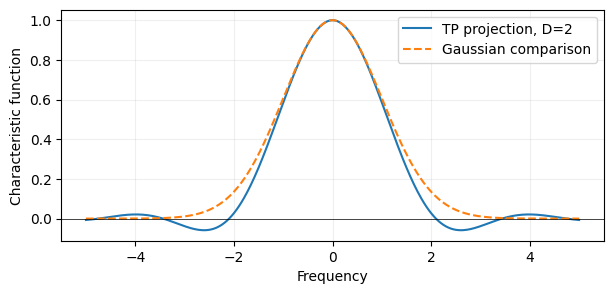

In [4]:
# Inspect the actual target: it differs from the Gaussian CF.
cf_check = ClasswiseQGaussianReg(D, q=0.0)
frequencies = torch.linspace(-5, 5, 401, dtype=torch.float64)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(frequencies, cf_check.projected_cf(frequencies), label=f'TP projection, D={D}')
ax.plot(frequencies, torch.exp(-frequencies.square() / 2), '--', label='Gaussian comparison')
ax.axhline(0, color='black', linewidth=0.5)
ax.set(xlabel='Frequency', ylabel='Characteristic function')
ax.legend(); ax.grid(alpha=0.2)
plt.show()

## Training objectives and treatment of compact support

The head returns **joint densities**, not logits. A true TP NLL is infinite
outside the target class support, which includes most initial embeddings.
Clipping densities would give flat gradients there. Use the existing EDA
joint Fenchel–Young loss instead:

$$
\ell_{\mathrm{FY}}(z,y)=\frac12-\frac{2}{D+4}\sum_c\pi_c^2\tau
+\pi_y\left(\tfrac12Q_y(z)+\tau\right).
$$

This retains gradients outside support. The comparison is:

- **FYLoss**: mean attached FY loss from `qgda.py` at q=0.
- **TPRegFYLoss**: FY plus $\lambda_{\mathrm{TP}}\mathcal{R}_{\mathrm{TP}}$.

TPReg starts after 5 FY-only epochs, ramping to its final weight over 5 epochs.
This is an explicit optimization choice carried over from the source experiment.
All runs share initial parameters, batch order, total epochs, and fixed head
geometry. Encoder parameters and class-prior logits are optimized.

A prediction is **uncovered** if every class density is zero. It receives label
`-1` and counts as incorrect; `argmax` never silently assigns such points to
class 0. Report both accuracy and coverage. The input Gaussian classes overlap,
whereas the target TP supports have radius $\sqrt{3}$ and pairwise mean
distance $6>2\sqrt{3}$, so they are disjoint. A deterministic
encoder therefore cannot map every overlapping input class exactly to those
targets. Held-out shape and support diagnostics expose this limitation.

In [5]:
def predict_with_support(scores):
    covered = scores.max(1).values > 0
    prediction = scores.argmax(1).masked_fill(~covered, -1)
    return prediction, covered


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = covered_count = total = 0
    model_device = next(model.parameters()).device
    for X, y in loader:
        X, y = X.to(model_device), y.to(model_device) - LABEL_OFFSET
        prediction, covered = predict_with_support(model(X))
        correct += (prediction == y).sum().item()
        covered_count += covered.sum().item()
        total += len(y)
    return dict(accuracy=correct / total, coverage=covered_count / total)


plot_indices = torch.randperm(len(train_ds), generator=torch.Generator().manual_seed(137))[:PLOT_SIZE]
embedding_ld = DataLoader(Subset(train_ds, plot_indices.tolist()),
                          batch_size=EVAL_BATCH_SIZE, shuffle=False,
                          generator=torch.Generator().manual_seed(137))


@torch.no_grad()
def capture_embeddings(model):
    model.eval()
    embeddings, labels = [], []
    for X, y in embedding_ld:
        embeddings.append(model.encoder(X.to(device)).cpu())
        labels.append(y)
    return dict(embeddings=torch.cat(embeddings), labels=torch.cat(labels),
                centers=model.head.mu.detach().cpu().clone(),
                variance=model.head.variance.detach().cpu().clone(),
                tau=model.head.tau().detach().cpu().clone(),
                radius=model.head.support_radius.item(),
                priors=model.head.priors().detach().cpu().clone())


def tpreg_weight_for_epoch(epoch):
    if epoch <= tpreg_warmup_epochs:
        return 0.0
    return tp_weight * min(1.0, (epoch - tpreg_warmup_epochs) / max(1, tpreg_ramp_epochs))


def train_comparison_run(loss_name, initial_state):
    torch.manual_seed(comparison_seed)
    model = DeepTPDA(NUM_CLASSES, D).to(device)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters())
    regularizer = ClasswiseQGaussianReg(D, num_slices=num_slices,
                                   num_points=num_integration_points, q=0.0).to(device)
    run_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                             generator=torch.Generator().manual_seed(comparison_seed))
    snapshots, history = {}, []
    step = 0
    for epoch in range(1, max(checkpoint_epochs) + 1):
        model.train()
        loss_sum = fy_sum = penalty_sum = correct = covered_count = total = 0
        weight = tpreg_weight_for_epoch(epoch) if loss_name == 'TPRegFYLoss' else 0.0
        for X, y in run_loader:
            X, y = X.to(device), y.to(device) - LABEL_OFFSET
            z = model.encoder(X)
            fy = qgaussian_joint_fy_loss(model.head, z, y).mean()
            penalty = z.new_zeros(())
            if weight:
                penalty = regularizer(
                    z, y, model.head.mu, radius=model.head.support_radius, step=step,
                )
            loss = fy + weight * penalty
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite {loss_name} at epoch {epoch}, step {step}')
            with torch.no_grad():
                prediction, covered = predict_with_support(model.head(z))
                correct += (prediction == y).sum().item()
                covered_count += covered.sum().item()
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            n = len(y)
            loss_sum += loss.item() * n
            fy_sum += fy.item() * n
            penalty_sum += penalty.item() * n
            total += n
            step += 1
        test = evaluate(model, test_ld)
        row = dict(epoch=epoch, loss=loss_sum / total, fy=fy_sum / total,
                   penalty=penalty_sum / total, regularization_weight=weight,
                   train_accuracy=correct / total, train_coverage=covered_count / total,
                   test_accuracy=test['accuracy'], test_coverage=test['coverage'])
        history.append(row)
        if epoch in checkpoint_epochs:
            snapshots[epoch] = capture_embeddings(model)
            print(f"[{loss_name} epoch {epoch:03d}] FY={row['fy']:.4f} "
                  f"penalty={row['penalty']:.4f} weight={weight:.2f} "
                  f"test acc={row['test_accuracy']:.4f} coverage={row['test_coverage']:.4f}")
    return model.eval().cpu(), snapshots, history

## Train both objectives

Test data reports performance; it does not select checkpoints or tune the settings.

In [6]:
torch.manual_seed(comparison_seed)
initial_state = deepcopy(DeepTPDA(NUM_CLASSES, D).state_dict())
comparison_models, embedding_snapshots, training_history = {}, {}, {}
for loss_name in loss_names:
    (comparison_models[loss_name], embedding_snapshots[loss_name],
     training_history[loss_name]) = train_comparison_run(loss_name, initial_state)

[FYLoss epoch 001] FY=0.6501 penalty=0.0000 weight=0.00 test acc=0.3513 coverage=0.3513
[FYLoss epoch 005] FY=0.4795 penalty=0.0000 weight=0.00 test acc=0.9167 coverage=0.9170
[FYLoss epoch 010] FY=0.4728 penalty=0.0000 weight=0.00 test acc=0.9477 coverage=0.9480
[FYLoss epoch 100] FY=0.4572 penalty=0.0000 weight=0.00 test acc=0.9888 coverage=0.9908
[TPRegFYLoss epoch 001] FY=0.6501 penalty=0.0000 weight=0.00 test acc=0.3513 coverage=0.3513
[TPRegFYLoss epoch 005] FY=0.4795 penalty=0.0000 weight=0.00 test acc=0.9167 coverage=0.9170
[TPRegFYLoss epoch 010] FY=0.4843 penalty=1.9497 weight=1.00 test acc=0.9080 coverage=0.9083
[TPRegFYLoss epoch 100] FY=0.4815 penalty=1.3715 weight=1.00 test acc=0.9330 coverage=0.9337


## Compare embeddings across epochs

Every panel uses the same training examples and coordinate limits. Crosses mark
fixed means; dashed circles mark **actual TP support boundaries**, not Gaussian
confidence ellipses. Shading uses TP joint densities and the saved class priors;
the white background is outside all supports.

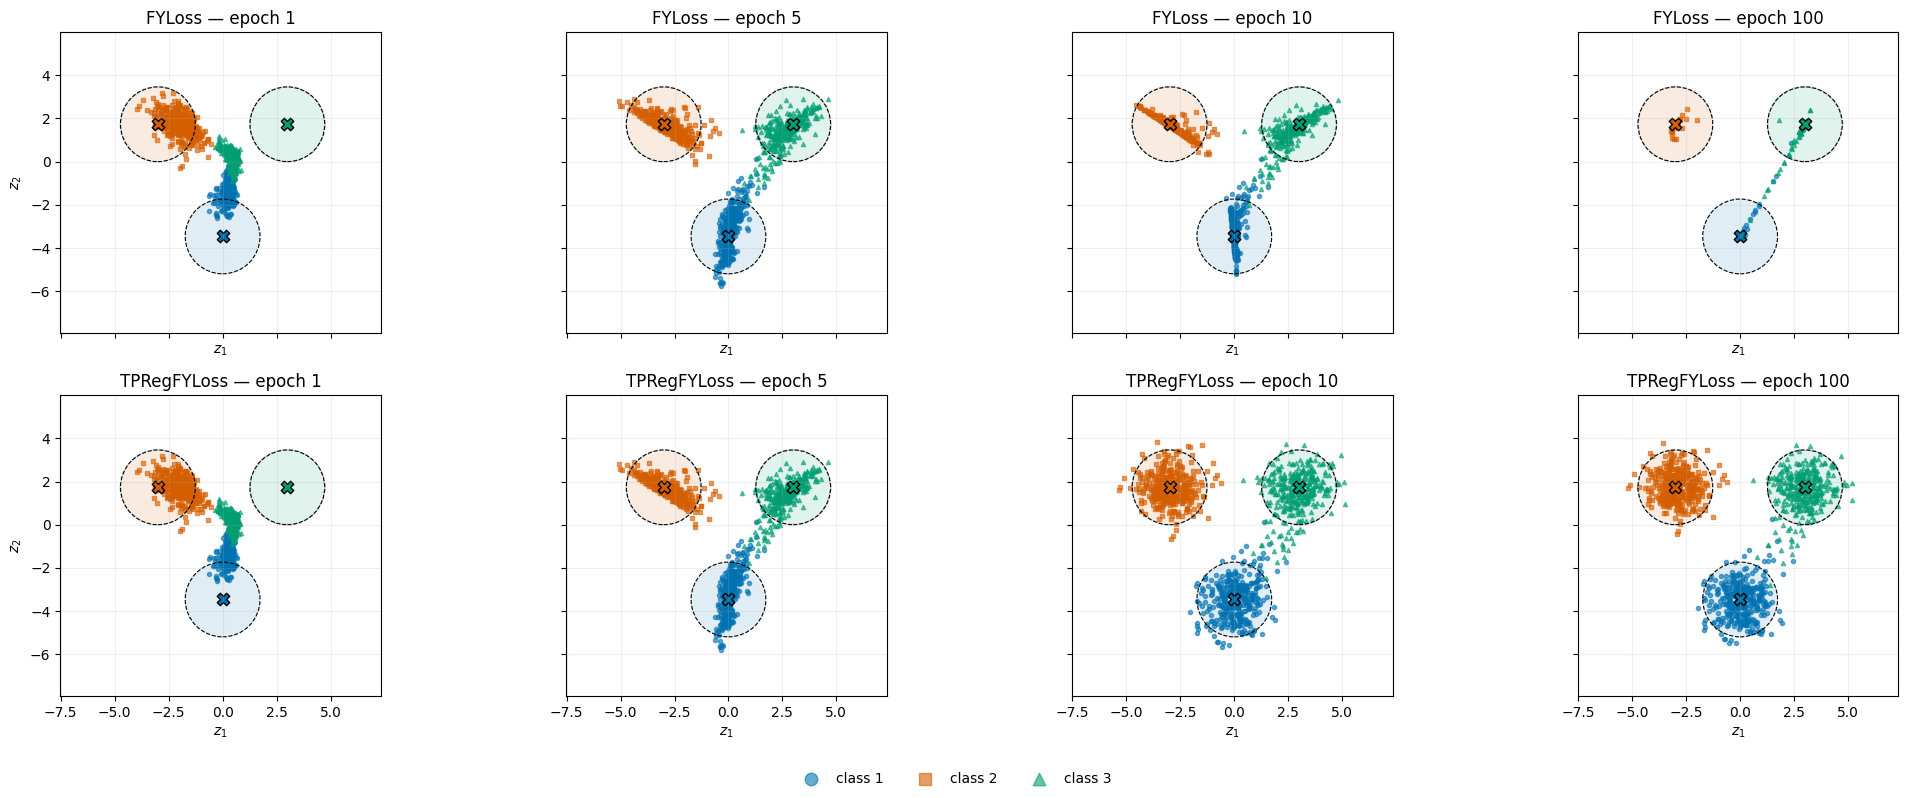

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle

colors = ['#0072B2', '#D55E00', '#009E73']
markers = ['o', 's', '^']
plot_dir.mkdir(parents=True, exist_ok=True)
all_points = torch.cat([
    snapshot['embeddings'] for snapshots in embedding_snapshots.values()
    for snapshot in snapshots.values()
] + [snapshot['centers'] for snapshots in embedding_snapshots.values()
     for snapshot in snapshots.values()])
margin = 1.25 * max(s['radius'] for snaps in embedding_snapshots.values() for s in snaps.values())
low = all_points.min(0).values.numpy() - margin
high = all_points.max(0).values.numpy() + margin
xx, yy = np.meshgrid(np.linspace(low[0], high[0], 240), np.linspace(low[1], high[1], 240))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(len(loss_names), len(checkpoint_epochs),
                         figsize=(21, 4 * len(loss_names)), sharex=True, sharey=True, squeeze=False)
for row, loss_name in enumerate(loss_names):
    for col, epoch in enumerate(checkpoint_epochs):
        ax = axes[row, col]
        snapshot = embedding_snapshots[loss_name][epoch]
        Z, Y = snapshot['embeddings'].numpy(), snapshot['labels'].numpy()
        centers = snapshot['centers'].numpy()
        squared_distance = ((grid[:, None] - centers[None]) ** 2).sum(-1)
        densities = np.maximum(-snapshot['tau'].numpy()[None] - 0.5 * squared_distance / float(snapshot['variance']), 0)
        scores = densities * snapshot['priors'].numpy()[None]
        regions = np.where(scores.max(1) > 0, scores.argmax(1) + 1, 0).reshape(xx.shape)
        ax.contourf(xx, yy, regions, levels=np.arange(NUM_CLASSES + 2) - 0.5,
                    cmap=ListedColormap(['white'] + colors), alpha=0.12)
        for c in range(NUM_CLASSES):
            mask = Y == c + LABEL_OFFSET
            ax.scatter(Z[mask, 0], Z[mask, 1], s=9, alpha=0.6,
                       color=colors[c], marker=markers[c], label=f'class {c + LABEL_OFFSET}')
            ax.scatter(*centers[c], marker='X', s=80, color=colors[c], edgecolor='black')
            ax.add_patch(Circle(centers[c], snapshot['radius'], fill=False,
                                edgecolor='black', linestyle='--', linewidth=0.8))
        ax.set_title(f'{loss_name} — epoch {epoch}')
        ax.set_xlim(low[0], high[0]); ax.set_ylim(low[1], high[1])
        ax.set_aspect('equal', adjustable='box')
        ax.grid(alpha=0.2)
        ax.set_xlabel('$z_1$')
        if col == 0:
            ax.set_ylabel('$z_2$')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=NUM_CLASSES, frameon=False, markerscale=3)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(plot_dir / 'synth_tp_fy_tpreg_epochs.png', dpi=180, bbox_inches='tight')
plt.show()